# Chương 3 — Bag of Visual Words (Local — Pure Julia)

Phiên bản chạy trực tiếp trên **máy local**, dùng thẳng mã nguồn `applications.jl` và `negFIN` tự viết của nhóm.

### Hướng dẫn chạy trên máy Local
1. Dữ liệu `data/chapter3/digits8x8.csv` đã có sẵn trong repository.
2. Chọn **Kernel: Julia** trong VS Code hoặc Jupyter.
3. Bấm **Run All** để chạy kiểm thử và xuất kết quả tại `results/chapter3/visual_words/`.

## Phần 1: Nạp Module `Applications` Từ Thư Mục Dự Án

In [1]:
using Pkg: Pkg

function find_project_root()::String
    dir = pwd()
    for _ in 1:4
        if isfile(joinpath(dir, "Project.toml")) &&
           isdir(joinpath(dir, "src", "applications"))
            return dir
        end
        parent = dirname(dir)
        parent == dir && break
        dir = parent
    end
    error("Không tìm thấy thư mục gốc chứa Project.toml")
end

const ROOT_DIR = find_project_root()
Pkg.activate(ROOT_DIR)
include(joinpath(ROOT_DIR, "src", "applications", "applications.jl"))
using .Applications: print_accuracy_table, print_enrichment_table, run_visual_words
println("Julia version: ", VERSION)
println("Project root:  ", ROOT_DIR)

  Activating 

Julia version: 1

project at `~/Documents/Material/AI/DataMining/Frequent_Itemset_Mining`


.11.9
Project root:  /Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining


## Phần 2: Chạy Kiểm Thử Tự Động Chương 3

In [2]:
include(joinpath(ROOT_DIR, "tests", "test_ch3_julia.jl"))

MARKET: 4 transactions; 4 itemsets; 2 rules; support PASS; 0.077 sec


  [apple] => [milk]: confidence=66.7%, lift=0.89. Goi y thu nghiem ban kem; chi la tuong quan, khong chung minh quan he nhan qua.
  [milk] => [apple]: confidence=66.7%, lift=0.89. Goi y thu nghiem ban kem; chi la tuong quan, khong chung minh quan he nhan qua.
Output: /var/folders/8l/7prcmx5n5zzg53q7bzstcnzc0000gn/T/jl_3hiJKm/market
VISUAL: 36 train + 12 test images; 47 itemsets, 41 patterns; support PASS
Accuracy baseline=0.4167, with patterns=0.3333
Output: /var/folders/8l/7prcmx5n5zzg53q7bzstcnzc0000gn/T/jl_odcDEk
Test Summary:                | Pass  Total  Time
Chapter 3 Julia applications |   27     27  7.9s


Test.DefaultTestSet("Chapter 3 Julia applications", Any[Test.DefaultTestSet("negFIN integration and support", Any[], 7, false, false, true, 1.795884321623014e9, 1.795884324033039e9, false, "/Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/tests/test_ch3_julia.jl"), Test.DefaultTestSet("association rules and lift", Any[], 3, false, false, true, 1.79588432403309e9, 1.795884324261734e9, false, "/Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/tests/test_ch3_julia.jl"), Test.DefaultTestSet("market input, output and naming", Any[], 5, false, false, true, 1.795884324261763e9, 1.795884325503399e9, false, "/Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/tests/test_ch3_julia.jl"), Test.DefaultTestSet("repeatable visual descriptors and k-means", Any[], 5, false, false, true, 1.795884325503432e9, 1.795884325956132e9, false, "/Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/

## Phần 3: Chạy Bag of Visual Words & Đánh Giá Phân Loại

- Sử dụng 9 dense gradient descriptors 6 chiều/ảnh (**không phải SIFT/ORB**), K-means tự cài (`K = 16`, `seed = 42`), khai thác bằng `negfin_optimized` (`minsup = 0.12`).
- Kết quả lưu tại `results/chapter3/visual_words/` (`summary.txt`, `patterns_by_class.csv`, `test_accuracy_comparison.csv`, `enriched_patterns.svg`, `digits_samples.svg`).

VISUAL: 448 train + 152 test images; 154 itemsets, 60 patterns; support PASS
Accuracy baseline=0.7961, with patterns=0.7895
Output: /Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/results/chapter3/visual_words

=== VISUAL WORDS SUMMARY ===
Dataset: UCI optical recognition digits (8x8 grayscale)
Train/test images: 448/152; seed: 42
Descriptors: 9 local gradient patches per image, 6 values per patch; NOT SIFT
K-means codebook: 16 words, trained on train images only
Algorithm: optimized; minsup: 0.12
Frequent itemsets: 154; selected patterns: 60
Mining elapsed_sec: 0.0069
Support cross-check: PASS
Nearest-centroid accuracy words only: 0.7961
Nearest-centroid accuracy + FIM patterns: 0.7895
Accuracy improvement is not guaranteed; check actual results.

=== SO SÁNH ĐỘ CHÍNH XÁC NEAREST-CENTROID ===
--------------------------------------------------------
Representation               | Features | Test Accuracy
--------------------------------------------------

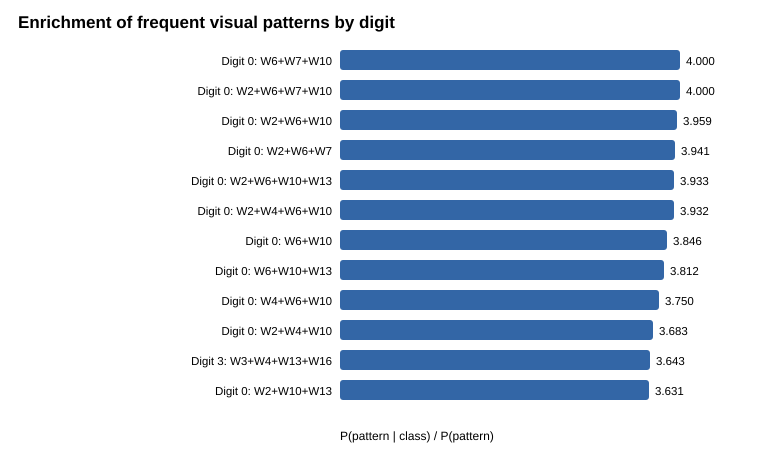

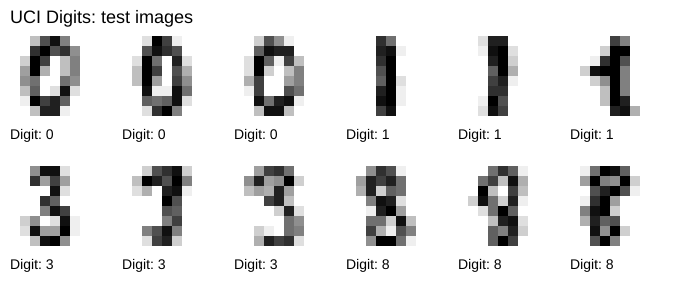

In [3]:
visual_res = run_visual_words(;
    minsup=0.12,
    words=16,
    seed=42,
    algo=:optimized,
)

visual_dir = joinpath(ROOT_DIR, "results", "chapter3", "visual_words")
println("\n=== VISUAL WORDS SUMMARY ===")
println(read(joinpath(visual_dir, "summary.txt"), String))
println("=== SO SÁNH ĐỘ CHÍNH XÁC NEAREST-CENTROID ===")
print_accuracy_table(joinpath(visual_dir, "test_accuracy_comparison.csv"))
println("\n=== TOP-10 PATTERN ĐẶC TRƯNG (ENRICHMENT) ===")
print_enrichment_table(joinpath(visual_dir, "patterns_by_class.csv"))
display("image/svg+xml", read(joinpath(visual_dir, "enriched_patterns.svg"), String))
display("image/svg+xml", read(joinpath(visual_dir, "digits_samples.svg"), String))